<a href="https://colab.research.google.com/github/jayjadhav33/E-Commerce-Sales-Analysis/blob/main/Olist_Sales_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Data  Loading and Cleaning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

sns.set_style("whitegrid")

# Unzip the dataset
with zipfile.ZipFile('/content/archive.zip') as z:
    z.extractall('/content/data')

import os
print(os.listdir('/content/data'))

['olist_products_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_items_dataset.csv', 'olist_sellers_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_customers_dataset.csv', 'olist_order_reviews_dataset.csv', 'product_category_name_translation.csv']


In [2]:
path = '/content/data/'
orders    = pd.read_csv(path + 'olist_orders_dataset.csv')
items     = pd.read_csv(path + 'olist_order_items_dataset.csv')
products  = pd.read_csv(path + 'olist_products_dataset.csv')
reviews   = pd.read_csv(path + 'olist_order_reviews_dataset.csv')
customers = pd.read_csv(path + 'olist_customers_dataset.csv')
trans     = pd.read_csv(path + 'product_category_name_translation.csv')

for name, d in [('orders',orders),('items',items),('products',products),
                ('reviews',reviews),('customers',customers)]:
    print(name, d.shape)

orders (99441, 8)
items (112650, 7)
products (32951, 9)
reviews (99224, 7)
customers (99441, 5)


In [3]:
for name, d in [('orders',orders),('items',items),('products',products),
                ('reviews',reviews),('customers',customers)]:
    print("=====", name)
    print(d.isnull().sum()[d.isnull().sum()>0])
    print("Duplicate rows:", d.duplicated().sum())

===== orders
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64
Duplicate rows: 0
===== items
Series([], dtype: int64)
Duplicate rows: 0
===== products
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64
Duplicate rows: 0
===== reviews
review_comment_title      87656
review_comment_message    58247
dtype: int64
Duplicate rows: 0
===== customers
Series([], dtype: int64)
Duplicate rows: 0


In [4]:
date_cols = ['order_purchase_timestamp','order_approved_at',
             'order_delivered_carrier_date','order_delivered_customer_date',
             'order_estimated_delivery_date']
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

orders.dtypes

,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


In [5]:
# Remove duplicate rows, if any
orders = orders.drop_duplicates()
items = items.drop_duplicates()

# Some orders have more than one review. Keep the latest per order.
reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'])
reviews = (reviews.sort_values('review_creation_date')
                  .drop_duplicates(subset='order_id', keep='last'))

# Missing product category -> 'unknown'
products['product_category_name'] = products['product_category_name'].fillna('unknown')

# Keep only delivered orders (cancelled orders are not real sales)
orders = orders[orders['order_status'] == 'delivered']
print(orders.shape)

(96478, 8)


In [6]:
df = items.merge(orders[['order_id','customer_id','order_purchase_timestamp']],
                 on='order_id', how='inner')
df = df.merge(products[['product_id','product_category_name']],
              on='product_id', how='left')
df = df.merge(trans, on='product_category_name', how='left')
df = df.merge(customers[['customer_id','customer_state']],
              on='customer_id', how='left')

# English category name; fill gaps
df['category'] = df['product_category_name_english'].fillna('unknown')

# Revenue = item price
df['revenue'] = df['price']

# Time columns
df['year']  = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)

print(df.shape)
df.head()

(110197, 16)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_purchase_timestamp,product_category_name,product_category_name_english,customer_state,category,revenue,year,month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,cool_stuff,cool_stuff,RJ,cool_stuff,58.90,2017,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,pet_shop,pet_shop,SP,pet_shop,239.90,2017,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,moveis_decoracao,furniture_decor,MG,furniture_decor,199.00,2018,2018-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,perfumaria,perfumery,SP,perfumery,12.99,2018,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,ferramentas_jardim,garden_tools,SP,garden_tools,199.90,2017,2017-02


In [7]:
df = df[df['year'] == 2017].copy()
print(df['month'].unique())
print(df.shape)

['2017-09' '2017-04' '2017-02' '2017-05' '2017-12' '2017-08' '2017-11'
 '2017-03' '2017-10' '2017-01' '2017-06' '2017-07']
(49556, 16)


In [8]:
order_df = (df.groupby('order_id')
              .agg(order_value=('revenue','sum'),
                   month=('month','first'),
                   state=('customer_state','first'))
              .reset_index())
order_df = order_df.merge(reviews[['order_id','review_score']],
                          on='order_id', how='left')
order_df.head()

,order_id,order_value,month,state,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,58.9,2017-09,RJ,5.0
1,00018f77f2f0320c557190d7a144bdd3,239.9,2017-04,SP,4.0
2,00042b26cf59d7ce69dfabb4e55b4fd9,199.9,2017-02,SP,5.0
3,00048cc3ae777c65dbb7d2a0634bc1ea,21.9,2017-05,MG,4.0
4,00054e8431b9d7675808bcb819fb4a32,19.9,2017-12,SP,4.0


# 2. Sales Analysis

In [26]:
# Q1: Which product category has the highest revenue?

cat_rev = df.groupby('category')['revenue'].sum().sort_values(ascending=False)

print("Q1: Which product category has the highest revenue?")
print("-" * 60)
print(f"Category with highest revenue : {cat_rev.index[0]} with revenue $ {cat_rev.iloc[0]:,.2f}")
print("\nRemaining categories and their revenue:")
for cat, rev in cat_rev.iloc[1:11].items():
    print(f"  {cat:<35} ${rev:>12,.2f}")

Q1: Which product category has the highest revenue?
------------------------------------------------------------
Category with highest revenue : bed_bath_table with revenue $ 490,596.92

Remaining categories and their revenue:
  watches_gifts                       $  475,610.71
  health_beauty                       $  473,833.00
  sports_leisure                      $  435,674.14
  computers_accessories               $  391,786.29
  cool_stuff                          $  381,414.30
  furniture_decor                     $  324,587.60
  toys                                $  299,056.71
  garden_tools                        $  256,949.20
  auto                                $  234,550.09
  housewares                          $  222,518.16


In [33]:
# Q2: Which month had peak sales?

monthly = df.groupby('month')['revenue'].sum()
monthly_sorted = monthly.sort_values(ascending=False)

print("Q2: Which month had peak sales?")
print("-" * 60)
print(f"Month with peak sales : {monthly_sorted.index[0]} with revenue ${monthly_sorted.iloc[0]:,.2f}")
print("\nRemaining months and their revenue:")
for m, rev in monthly_sorted.iloc[1:].items():
    print(f"  {m:<12} ${rev:>12,.2f}")

Q2: Which month had peak sales?
------------------------------------------------------------
Month with peak sales : 2017-11 with revenue $987,765.37

Remaining months and their revenue:
  2017-12      $  726,033.19
  2017-10      $  648,247.65
  2017-09      $  607,399.67
  2017-08      $  554,699.70
  2017-05      $  489,338.25
  2017-07      $  481,604.52
  2017-06      $  421,923.37
  2017-03      $  359,198.85
  2017-04      $  340,669.68
  2017-02      $  234,223.40
  2017-01      $  111,798.36


In [34]:
# Q3: Which region performs best?

state_rev = df.groupby('customer_state')['revenue'].sum().sort_values(ascending=False)
total_rev = state_rev.sum()

print("Q3: Which region (state) performs best?")
print("-" * 60)
print(f"Best performing state : {state_rev.index[0]} with revenue ${state_rev.iloc[0]:,.2f} "
      f"({state_rev.iloc[0]/total_rev*100:.1f}% of total)")
print("\nRemaining states and their revenue :")
for st, rev in state_rev.iloc[1:11].items():
    print(f"  {st:<5} ${rev:>12,.2f}   ({rev/total_rev*100:.1f}%)")

Q3: Which region (state) performs best?
------------------------------------------------------------
Best performing state : SP with revenue $2,136,258.96 (35.8% of total)

Remaining states and their revenue :
  RJ    $  876,499.71   (14.7%)
  MG    $  708,034.68   (11.9%)
  RS    $  350,792.78   (5.9%)
  PR    $  287,424.81   (4.8%)
  BA    $  227,453.44   (3.8%)
  SC    $  223,249.33   (3.7%)
  GO    $  133,801.01   (2.2%)
  DF    $  131,169.70   (2.2%)
  PE    $  116,445.99   (2.0%)
  ES    $  115,752.57   (1.9%)


In [35]:
# Q4: What is the average order value (AOV) trend?

aov = order_df.groupby('month')['order_value'].mean()

print("Q4: What is the average order value (AOV) trend?")
print("-" * 60)
print(f"Highest AOV : {aov.idxmax()} with AOV ${aov.max():,.2f}")
print(f"Lowest AOV  : {aov.idxmin()} with AOV ${aov.min():,.2f}")
print(f"Overall AOV for 2017 : ${order_df['order_value'].mean():,.2f}")

print("\nMonth-by-month AOV (chronological, with change from previous month):")
prev = None
for m, val in aov.items():
    if prev is None:
        print(f"  {m:<10} R$ {val:>8,.2f}")
    else:
        change = (val - prev) / prev * 100
        arrow = "▲" if change > 0 else "▼"
        print(f"  {m:<10} R$ {val:>8,.2f}   {arrow} {change:+.1f}%")
    prev = val

Q4: What is the average order value (AOV) trend?
------------------------------------------------------------
Highest AOV : 2017-01 with AOV $149.06
Lowest AOV  : 2017-07 with AOV $124.38
Overall AOV for 2017 : $137.31

Month-by-month AOV (chronological, with change from previous month):
  2017-01    R$   149.06
  2017-02    R$   141.70   ▼ -4.9%
  2017-03    R$   141.08   ▼ -0.4%
  2017-04    R$   147.92   ▲ +4.8%
  2017-05    R$   138.00   ▼ -6.7%
  2017-06    R$   134.58   ▼ -2.5%
  2017-07    R$   124.38   ▼ -7.6%
  2017-08    R$   132.29   ▲ +6.4%
  2017-09    R$   146.36   ▲ +10.6%
  2017-10    R$   144.76   ▼ -1.1%
  2017-11    R$   135.51   ▼ -6.4%
  2017-12    R$   131.69   ▼ -2.8%


In [36]:
# Q5: What is the review score distribution?

score_counts = order_df['review_score'].value_counts().sort_index()
score_pct = (score_counts / score_counts.sum() * 100).round(1)
most_common = score_counts.idxmax()

print("Q5: What is the customer review score distribution?")
print("-" * 60)
print(f"Most common review score : {int(most_common)} stars with {score_counts.max():,} orders "
      f"({score_pct[most_common]}%)")
print(f"Average review score     : {order_df['review_score'].mean():.2f} / 5")

print("\nFull distribution (descending order of number of orders):")
for score, cnt in score_counts.sort_values(ascending=False).items():
    print(f"  {int(score)} stars : {cnt:>6,} orders   ({score_pct[score]}%)")

Q5: What is the customer review score distribution?
------------------------------------------------------------
Most common review score : 5 stars with 25,475 orders (59.1%)
Average review score     : 4.17 / 5

Full distribution (descending order of number of orders):
  5 stars : 25,475 orders   (59.1%)
  4 stars :  8,735 orders   (20.3%)
  1 stars :  3,881 orders   (9.0%)
  3 stars :  3,674 orders   (8.5%)
  2 stars :  1,335 orders   (3.1%)


# 3. Visualisations

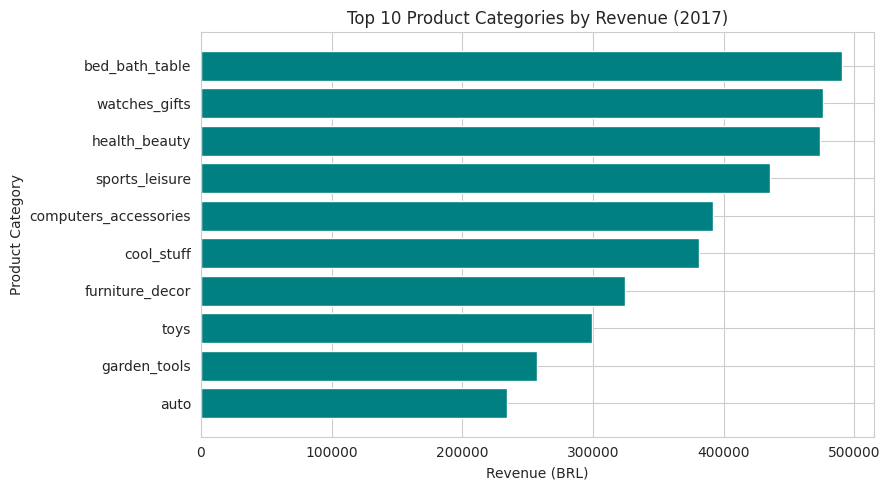

In [37]:
# CHART 1: Horizontal bar chart - Top 10 categories by revenue

top10 = cat_rev.head(10).sort_values()

plt.figure(figsize=(9, 5))
plt.barh(top10.index, top10.values, color='teal')
plt.title('Top 10 Product Categories by Revenue (2017)')
plt.xlabel('Revenue (BRL)')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()

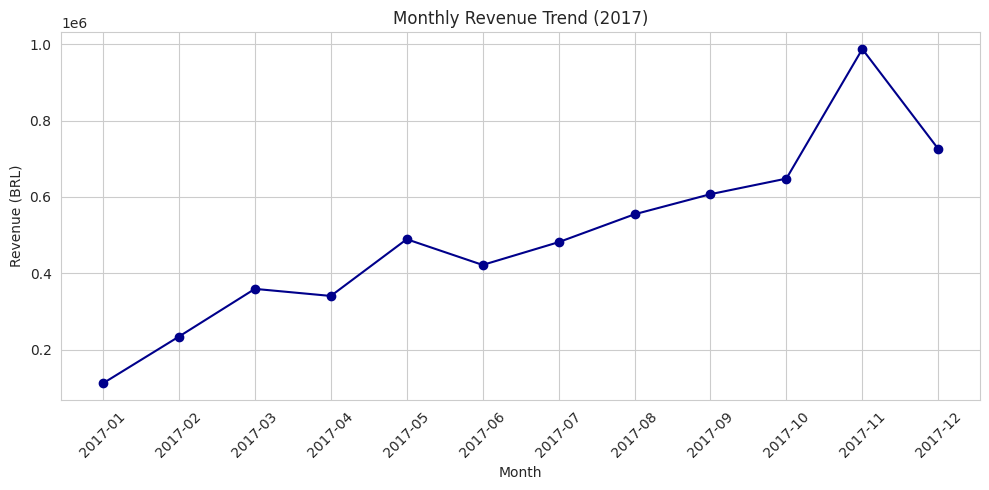

In [38]:
# CHART 2: Line chart - Monthly revenue trend

plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly.values,
         marker='o', color='darkblue')
plt.title('Monthly Revenue Trend (2017)')
plt.xlabel('Month')
plt.ylabel('Revenue (BRL)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

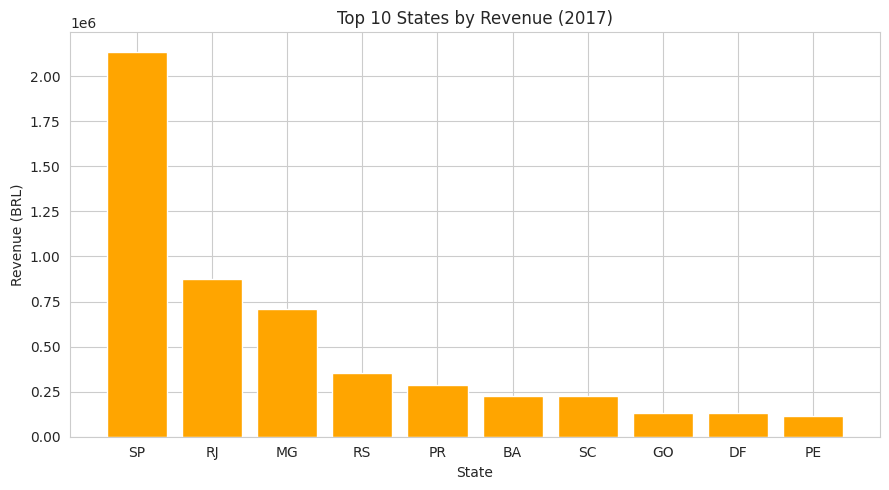

In [39]:
# CHART 3: Vertical bar chart - Top 10 states (regions) by revenue

top_states = state_rev.head(10)

plt.figure(figsize=(9, 5))
plt.bar(top_states.index, top_states.values,
        color='orange')
plt.title('Top 10 States by Revenue (2017)')
plt.xlabel('State')
plt.ylabel('Revenue (BRL)')
plt.tight_layout()
plt.show()

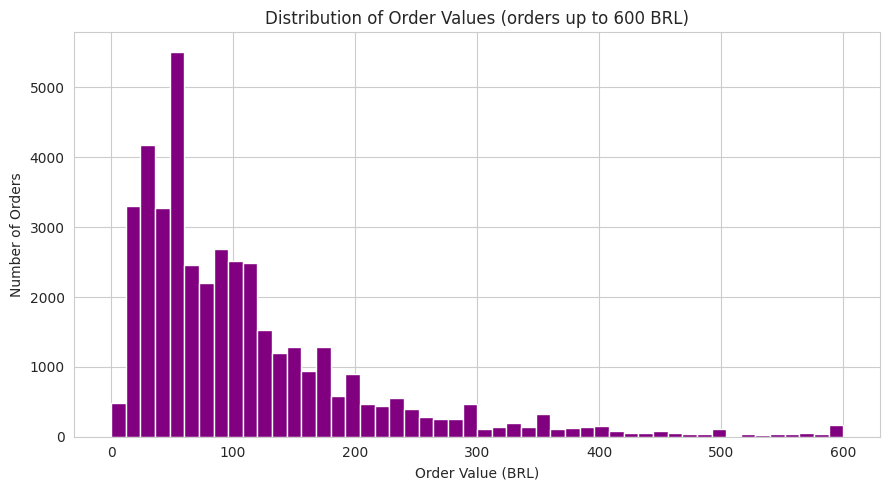

In [41]:
# CHART 4: Histogram - How order values are distributed

plt.figure(figsize=(9, 5))
plt.hist(order_df['order_value'],
         bins=50,
         range=(0, 600),
         color='purple')
plt.title('Distribution of Order Values (orders up to 600 BRL)')
plt.xlabel('Order Value (BRL)')
plt.ylabel('Number of Orders')
plt.tight_layout()
plt.show()

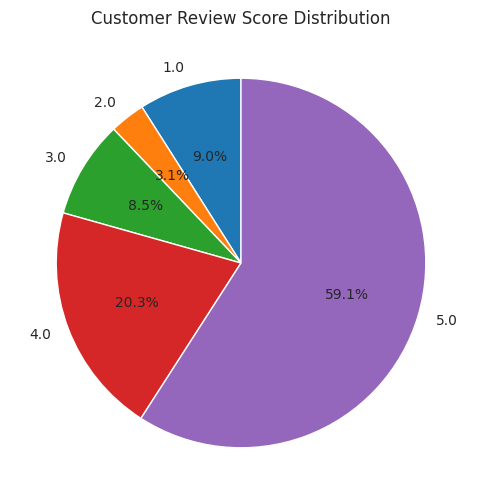

In [42]:
# CHART 5: Pie chart - Share of each review score (1 to 5 stars)

plt.figure(figsize=(6, 6))
plt.pie(score_counts.values,
        labels=score_counts.index,
        autopct='%1.1f%%',
        startangle=90)
plt.title('Customer Review Score Distribution')
plt.show()

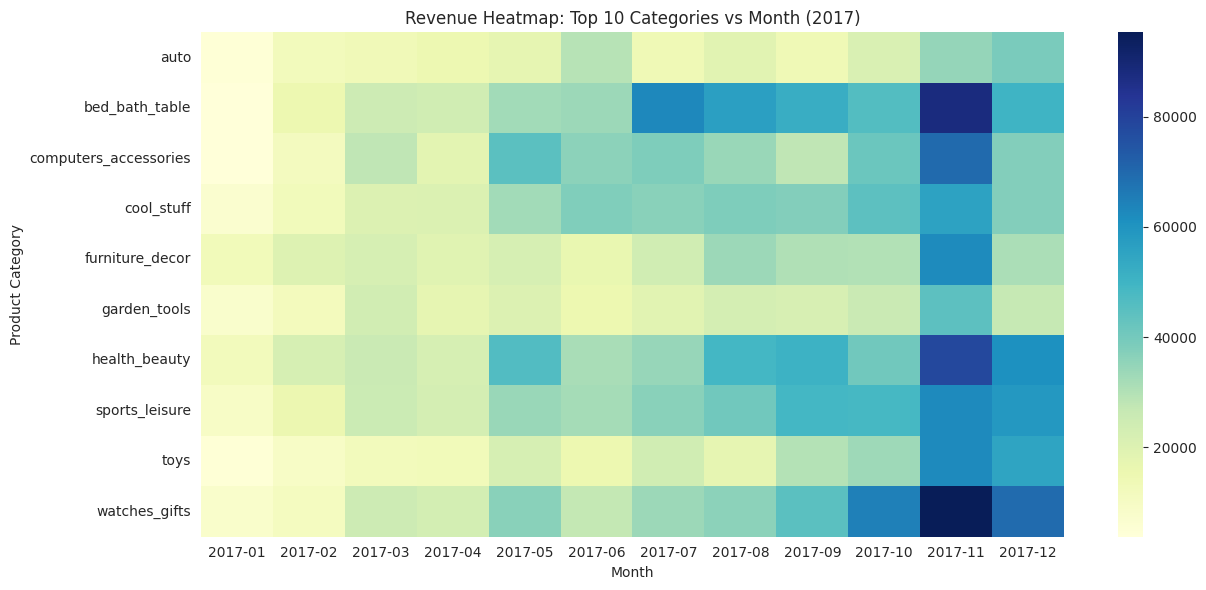

In [43]:
# CHART 6: Heatmap - Revenue of top 10 categories across months

top_cats = cat_rev.head(10).index

# Build a table: rows = categories, columns = months, cells = total revenue
heat = (df[df['category'].isin(top_cats)]
          .pivot_table(index='category',
                       columns='month',
                       values='revenue',
                       aggfunc='sum'))

plt.figure(figsize=(13, 6))
sns.heatmap(heat, cmap='YlGnBu')
plt.title('Revenue Heatmap: Top 10 Categories vs Month (2017)')
plt.xlabel('Month')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()

#4 Dashboard

In [44]:
total_revenue = df['revenue'].sum()
total_orders  = df['order_id'].nunique()
top_category  = cat_rev.idxmax()
best_month    = monthly.idxmax()

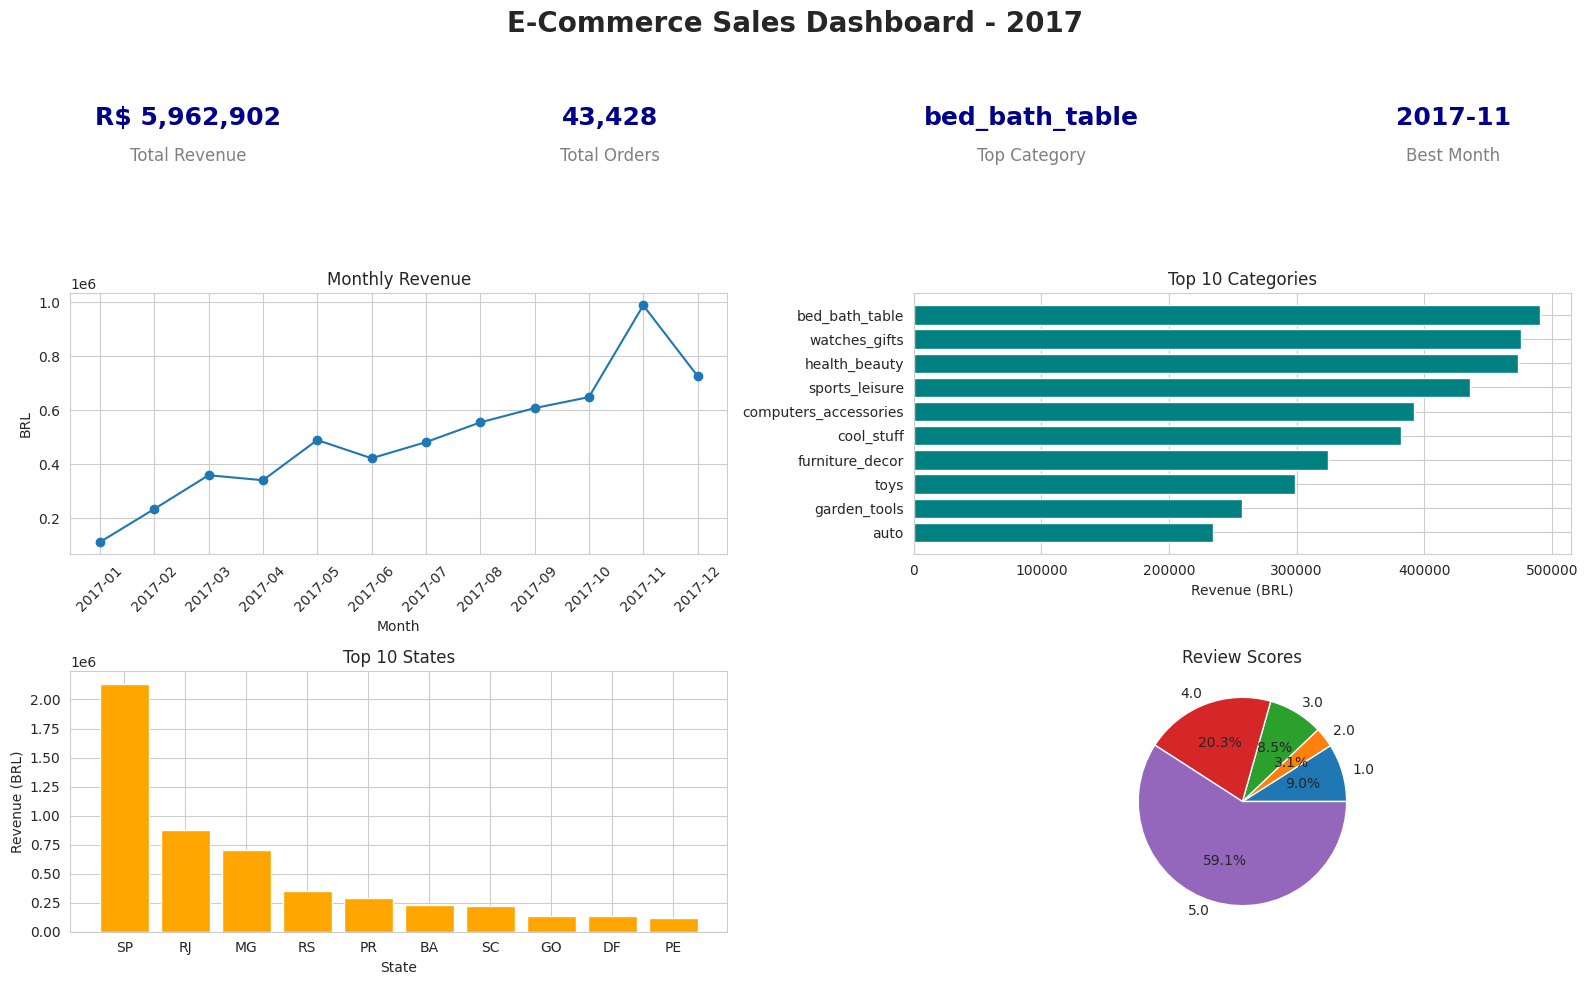

In [45]:
fig = plt.figure(figsize=(16,10))
gs = fig.add_gridspec(3, 4, height_ratios=[0.6,2,2])
fig.suptitle('E-Commerce Sales Dashboard - 2017', fontsize=20, fontweight='bold')

# KPI boxes (top row)
kpis = [('Total Revenue', f'R$ {total_revenue:,.0f}'),
        ('Total Orders', f'{total_orders:,}'),
        ('Top Category', top_category),
        ('Best Month', best_month)]
for i,(label,val) in enumerate(kpis):
    ax = fig.add_subplot(gs[0,i]); ax.axis('off')
    ax.text(0.5,0.65,val,ha='center',fontsize=18,fontweight='bold',color='darkblue')
    ax.text(0.5,0.2,label,ha='center',fontsize=12,color='gray')

# Charts
ax1 = fig.add_subplot(gs[1,:2])
ax1.plot(monthly.index, monthly.values, marker='o')
ax1.set_title('Monthly Revenue'); ax1.set_xlabel('Month'); ax1.set_ylabel('BRL')
ax1.tick_params(axis='x', rotation=45)

ax2 = fig.add_subplot(gs[1,2:])
ax2.barh(top10.index, top10.values, color='teal')
ax2.set_title('Top 10 Categories'); ax2.set_xlabel('Revenue (BRL)')

ax3 = fig.add_subplot(gs[2,:2])
ax3.bar(top_states.index, top_states.values, color='orange')
ax3.set_title('Top 10 States'); ax3.set_xlabel('State'); ax3.set_ylabel('Revenue (BRL)')

ax4 = fig.add_subplot(gs[2,2:])
ax4.pie(score_counts.values, labels=score_counts.index, autopct='%1.1f%%')
ax4.set_title('Review Scores')

plt.tight_layout(rect=[0,0,1,0.95])
plt.savefig('dashboard.png', dpi=150)
plt.show()

In [ ]:
'''4. Business Insights Report

Scope: Delivered orders, calendar year 2017
Key metrics: Total revenue $5,962,902 | Total orders 43,428 | Average order value $137.31 | Average review score 4.17 / 5

Insight 1: Category revenue is well diversified (Chart 1)
Bed, bath & table is the leading category at 490,597 (8.2% of total revenue).
watches_gifts ($475,611) and health_beauty ($473,833) are both well behind the leader by less than $17k.
The top 3 are responsible for circa 24% of the revenue and the top 10 for circa 63% so no single category is dominant in any way.
Recommendation: concentrate your inventory and marketing spend on the top 5 categories (all of which are well over $390k in revenue). Do some targeted promotions in the mid ranked categories (furniture_decor, toys) to see if there's any growth potential in those.

Insight 2: Demand peaks sharply in November (Chart 2)
Monthly revenue rose from $111,798 in January to $987,765 in November (an increase of some 8.8x).
Nov revenue was up 52% on Oct and then down 26% in Dec ($726,033).
The November peak is very much down to Black Friday and pre-holiday demand. The data doesn't actually prove that and some of the increase is obviously just due to the general growth of the business.
Recommendation: Finalise the stock, logistics capacity and advertising budgets before October. Run a follow-up campaign in December to offset the fall off after the peak.

Insight 3: Revenue is geographically concentrated (Chart 3)
Sao Paulo (SP) takes in $2,136,259 (35.8% of revenue) which is about 2.4 times more than Rio de Janeiro (RJ) who is second at 14.7%.
SP, RJ and MG account for some 62% of the revenue and the top 10 states are responsible for some 87%.
Recommendation: Keep the SP, RJ and MG markets at the heart of the business via fast delivery and loyalty programmes. Reduce the regional exposure by running a pilot of shipping discounts and local campaigns in RS, PR and BA.

Insight 4: Growth is driven by order volume, not basket size (Chart 4)
Monthly average order value (AOV) remained in pretty much the same ball park at $124 to $149 despite the revenue being up nearly 9x.
AOV was lowest in July at $124.38 and up 10.6% in September to $146.36.
Recommendation: Introduce a free shipping threshold of circa $150/$170 and use bundle deals (e.g. 'buy 2 save 1') to drive basket size up. Look at what it was that drove the AOV uplift in September and try to do that again.

Insight 5: Satisfaction is strong, but 1-star reviews need attention (Chart 5)
Average rating is 4.17 (59.1% of orders received 5 stars, 20.3% received 4 stars).
1 star reviews (9.0%, 3881 orders) are occurring nearly three times as often as 2 star reviews (3.1%) which again points to specific failures (late delivery, damaged or wrong item, poor seller quality etc.) rather than a general level of dissatisfaction.
Recommendation: have a look at the 1 star orders by delivery time, product category and seller to establish the root cause and deal with that first. A 1/3 reduction in 1 star orders would make a real difference to the average.

Most Surprising Finding :
Revenue grew some 8.8x from Jan to Nov, average order value remained pretty much the same ($124 to $149). The growth was due to a massive increase in the number of orders rather than any increase in the size of the orders. The top three categories are also split by less than $17k so there is no one 'star' category.'''